# Revisión reproducible de la entrega final local

Este notebook **solo lee resultados**: verifica SHA-256, calcula resúmenes y dibuja figuras. No descarga datos ni entrena modelos. Ambos años de evaluación ya fueron inspeccionados; sus conclusiones son retrospectivas. Se necesita el repositorio y la carpeta de resultados enlazada; no se copian datos grandes.


In [1]:
# Localizar la entrega desde su carpeta, notebooks/ o la raíz del proyecto.
from pathlib import Path
import csv, gzip, hashlib, json
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

locations = [Path.cwd(), Path.cwd().parent, Path.cwd() / "delivery/final_regression_local_20261018"]
DELIVERY = next((path for path in locations if (path / "delivery_manifest.json").is_file()), None)
if DELIVERY is None:
    raise FileNotFoundError("Abra el notebook dentro del repositorio o su carpeta de entrega.")
manifest = json.loads((DELIVERY / "delivery_manifest.json").read_text(encoding="utf-8"))
RESULTS = (DELIVERY / manifest["results_relative_path"]).resolve()
def sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# Fallar ante un archivo modificado: un resultado nuevo exige reconstruir la entrega.
for artifact in manifest["input_artifacts"]:
    source = RESULTS / artifact["path"]
    if not source.is_file() or sha256(source) != artifact["sha256"]:
        raise RuntimeError("Hash de evidencia no coincide: " + artifact["path"])
print("Archivos de evidencia verificados:", len(manifest["input_artifacts"]))
print("Resultados:", RESULTS)
print("Pendientes:", manifest["missing_inputs"])


Archivos de evidencia verificados: 266
Resultados: C:\Users\Lenovo\Proyectos.py\MachineLearning\results\final_regression_20261018
Pendientes: []


## Protocolo y selección causal

La selección interna debe reconstruir el preprocesamiento con train en cada fold. El protocolo fija fechas, purga, espacios, presupuestos y semillas; su mera existencia no prueba que el código cumpla estas reglas.


In [2]:
protocol_path = RESULTS / "protocol.json"
if protocol_path.is_file():
    protocol = json.loads(protocol_path.read_text(encoding="utf-8"))
    print(json.dumps(protocol, ensure_ascii=False, indent=2))
else:
    print("Pendiente: protocol.json")


{
  "created_at_utc": "2026-10-18T18:23:30.873372+00:00",
  "publication": "LOCAL ONLY",
  "github_or_render_updates_authorized": false,
  "reference": "HAR-Ridge + XGBoost",
  "regression_families": [
    "kNN",
    "Ridge",
    "Lasso",
    "DecisionTree",
    "RandomForest",
    "XGBoost",
    "SVR"
  ],
  "methods": [
    "grid",
    "random",
    "bayesian",
    "genetic"
  ],
  "additional_family": "HAR-XG",
  "assets": [
    "BTCUSDT",
    "ETHUSDT",
    "BNBUSDT",
    "XRPUSDT"
  ],
  "target_windows": [
    7,
    14,
    21,
    28
  ],
  "horizons": [
    1,
    2,
    3,
    4,
    5,
    6,
    7
  ],
  "benchmark_combinations": 448,
  "additional_hybrid_combinations": 64,
  "final_models": 512,
  "outer": "Six original purged2024 blocks; ALL optimization repeated independently inside EACH outer train",
  "inner": "Two expanding chronological purged blocks per outer training support; three for final660-origin refit",
  "purge": "Maximum seven-target training label ends STR

## Métricas del bucle externo

Primero se promedian configuraciones y semillas dentro de cada fold; luego se calcula media y desviación **entre folds**. La agregación de ventanas describe objetivos diferentes.


rmse                       mae                  \
                             mean       std count      mean       std count   
model                                                                         
DecisionTree [bayesian]  0.654248  0.152160     6  0.472742  0.120212     6   
DecisionTree [genetic]   0.652629  0.151573     6  0.471463  0.119244     6   
DecisionTree [grid]      0.653783  0.164240     6  0.470749  0.129463     6   
DecisionTree [random]    0.673808  0.155238     6  0.481087  0.120474     6   
HAR-XG [bayesian]        0.497868  0.131285     6  0.372755  0.094733     6   
HAR-XG [genetic]         0.501602  0.132306     6  0.373913  0.096475     6   
HAR-XG [grid]            0.499273  0.139302     6  0.375560  0.102408     6   
HAR-XG [random]          0.524137  0.130921     6  0.391285  0.095696     6   
Lasso [bayesian]         0.492708  0.149398     6  0.368462  0.110944     6   
Lasso [genetic]          0.491984  0.154097     6  0.368888  0.114955     6   
Lasso [grid]             0.514015  0.161067     6  0.390004  0.125294     6   
Lasso [random]           0.524160  0.151321     6  0.400537  0.120868     6   
RandomForest [bayesian]  0.566617  0.156141     6  0.421909  0.114579     6   
RandomForest [genetic]   0.560342  0.157730     6  0.417642  0.115738     6   
RandomForest [grid]      0.551563  0.145310     6  0.415702  0.111035     6   
RandomForest [random]    0.568778  0.150159     6  0.422704  0.110007     6   
Ridge [bayesian]         0.500881  0.143968     6  0.372794  0.104478     6   
Ridge [genetic]          0.502413  0.147335     6  0.376258  0.112164     6   
Ridge [grid]             0.519161  0.160169     6  0.395221  0.123814     6   
Ridge [random]           0.524435  0.154672     6  0.402026  0.120115     6   
SVR [bayesian]           0.496078  0.147854     6  0.367813  0.110317     6   
SVR [genetic]            0.495407  0.146329     6  0.368194  0.109061     6   
SVR [grid]               0.496602  0.147437     6  0.370849  0.112113     6   
SVR [random]             0.496473  0.146329     6  0.370779  0.109161     6   
XGBoost [bayesian]       0.527816  0.140569     6  0.391037  0.106514     6   
XGBoost [genetic]        0.536877  0.131922     6  0.400949  0.098117     6   
XGBoost [grid]           0.520555  0.146827     6  0.388103  0.111305     6   
XGBoost [random]         0.533958  0.145368     6  0.394918  0.109019     6   
kNN [bayesian]           0.572112  0.130458     6  0.422441  0.105463     6   
kNN [genetic]            0.578494  0.127255     6  0.424610  0.104793     6   
kNN [grid]               0.555092  0.138840     6  0.411482  0.110098     6   
kNN [random]             0.559567  0.137884     6  0.416056  0.107981     6   

                              mse                        r2                  
                             mean       std count      mean       std count  
model                                                                        
DecisionTree [bayesian]  0.670734  0.310881     6  0.010440  0.259312     6  
DecisionTree [genetic]   0.661022  0.291855     6 -0.012176  0.303186     6  
DecisionTree [grid]      0.679666  0.379852     6  0.038612  0.217972     6  
DecisionTree [random]    0.720185  0.349120     6 -0.065470  0.305108     6  
HAR-XG [bayesian]        0.379550  0.190336     6  0.485615  0.127750     6  
HAR-XG [genetic]         0.392267  0.198800     6  0.475898  0.126785     6  
HAR-XG [grid]            0.388394  0.207475     6  0.486823  0.122507     6  
HAR-XG [random]          0.435706  0.223394     6  0.422100  0.127296     6  
Lasso [bayesian]         0.390164  0.216019     6  0.505190  0.150915     6  
Lasso [genetic]          0.392718  0.221867     6  0.507847  0.158475     6  
Lasso [grid]             0.431555  0.252068     6  0.464449  0.139671     6  
Lasso [random]           0.444427  0.238486     6  0.440084  0.143599     6  
RandomForest [bayesian]  0.501574  0.274216     6  0.313478  0.115067     6  
RandomForest [g

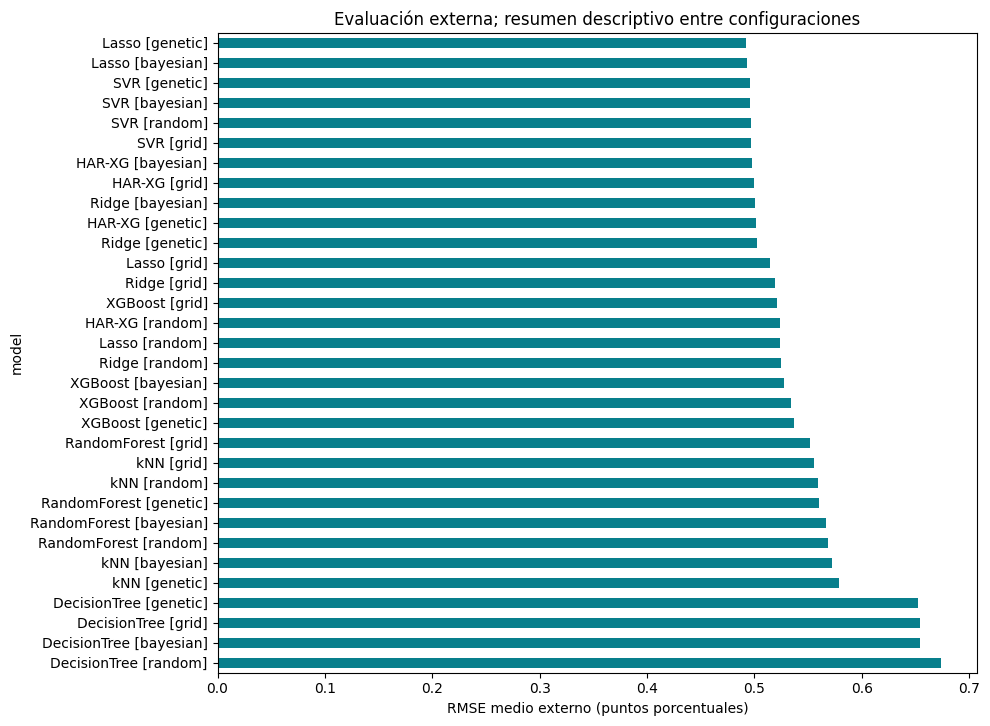

In [3]:
outer_path = RESULTS / "outer_metrics.csv"
if outer_path.is_file():
    outer = pd.read_csv(outer_path)
    metrics = [column for column in ["rmse", "mae", "mse", "r2"] if column in outer]
    by_fold = outer.groupby(["model", "outer_fold"])[metrics].mean()
    external_summary = by_fold.groupby("model").agg(["mean", "std", "count"])
    display(external_summary)
    means = by_fold.groupby("model")["rmse"].mean().sort_values()
    ax = means.plot.barh(figsize=(10, max(4, len(means) * .23)), color="#087f8c")
    ax.set_xlabel("RMSE medio externo (puntos porcentuales)")
    ax.set_title("Evaluación externa; resumen descriptivo entre configuraciones")
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()
else:
    print("Pendiente: outer_metrics.csv")


## Presupuesto, convergencia y costo de optimización

El mejor valor acumulado es pérdida de validación **interna**, no desempeño externo. La configuración ilustrada es la primera por orden de claves, sin elegirla por su resultado test. Grid con ocho evaluaciones es limitado cuando el espacio tiene más de ocho puntos.


,model,family,method,symbol,volatility_window,seed,outer_fold,trial,value,best_so_far,seconds,elapsed_seconds,params
0,DecisionTree [grid],DecisionTree,grid,BNBUSDT,14,42,1,0,0.261128,0.261128,0.064934,0.065040,"{""input_window"": 14, ""max_depth"": 4, ""min_samp..."
1,DecisionTree [grid],DecisionTree,grid,BNBUSDT,14,42,1,1,0.443764,0.261128,0.077611,0.142710,"{""input_window"": 14, ""max_depth"": 4, ""min_samp..."
2,DecisionTree [grid],DecisionTree,grid,BNBUSDT,14,42,1,2,0.214641,0.214641,0.098423,0.241190,"{""input_window"": 14, ""max_depth"": 4, ""min_samp..."
3,DecisionTree [grid],DecisionTree,grid,BNBUSDT,14,42,1,3,0.242349,0.214641,0.065687,0.306918,"{""input_window"": 14, ""max_depth"": 2, ""min_samp..."
4,DecisionTree [grid],DecisionTree,grid,BNBUSDT,14,42,1,4,0.266521,0.214641,0.043248,0.350214,"{""input_window"": 14, ""max_depth"": 2, ""min_samp..."
5,DecisionTree [grid],DecisionTree,grid,BNBUSDT,14,42,1,5,0.235343,0.214641,0.037172,0.387429,"{""input_window"": 14, ""max_depth"": 2, ""min_samp..."
6,DecisionTree [grid],DecisionTree,grid,BNBUSDT,14,42,1,6,0.270010,0.214641,0.056924,0.444400,"{""input_window"": 14, ""max_depth"": 8, ""min_samp..."
7,DecisionTree [grid],DecisionTree,grid,BNBUSDT,14,42,1,7,0.460685,0.214641,0.087523,0.531972,"{""input_window"": 14, ""max_depth"": 8, ""min_samp..."
8,DecisionTree [random],DecisionTree,random,BNBUSDT,14,42,1,0,0.219817,0.219817,0.064722,0.064869,"{""input_window"": 28, ""max_depth"": 4, ""min_samp..."
9,DecisionTree [random],DecisionTree,random,BNBUSDT,14,42,1,1,0.242349,0.219817,0.040349,0.105282,"{""input_window"": 14, ""max_depth"": 2, ""min_samp..."


,count,sum,mean
method,,,
bayesian,7168,9065.234664,1.264681
genetic,7168,8702.892473,1.214131
grid,7168,6072.981213,0.847235
random,7168,8094.156702,1.129207


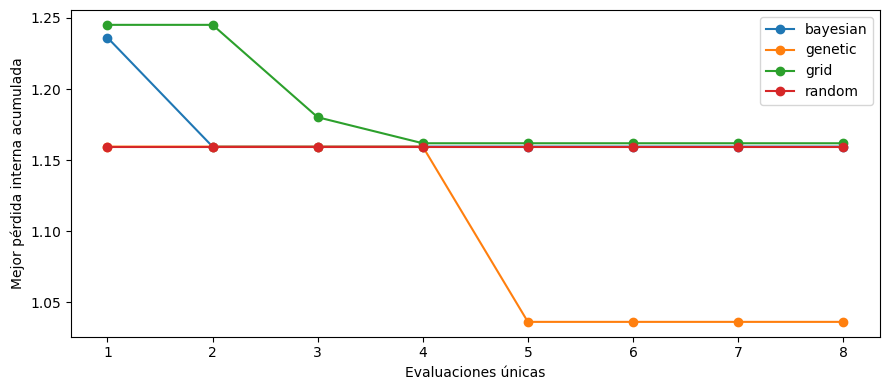

In [4]:
trials_path = RESULTS / "master_trials.csv"
if trials_path.is_file():
    trials = pd.read_csv(trials_path)
    display(trials.head(12))
    if {"method", "seconds"}.issubset(trials.columns):
        display(trials.groupby("method")["seconds"].agg(["count", "sum", "mean"]))
    keys = [key for key in ["family", "symbol", "volatility_window", "seed", "outer_fold"] if key in trials]
    selected = trials.sort_values(keys, kind="stable") if keys else trials
    if len(selected) and "best_so_far" in selected:
        first = selected.iloc[0]
        for key in keys:
            selected = selected[selected[key].eq(first[key])]
        fig, ax = plt.subplots(figsize=(9, 4))
        for method, records in selected.groupby("method"):
            trial_column = next((column for column in ["trial_number", "trial"] if column in records), None)
            if trial_column is None:
                raise ValueError("Falta el índice de evaluación: trial o trial_number")
            records = records.sort_values(trial_column, kind="stable")
            ax.plot(range(1, len(records) + 1), records["best_so_far"], marker="o", label=method)
        ax.set(xlabel="Evaluaciones únicas", ylabel="Mejor pérdida interna acumulada")
        ax.legend()
        plt.tight_layout()
        plt.show()
else:
    print("Pendiente: master_trials.csv")


## Auditoría retrospectiva frente al modelo vigente

La tabla separa métricas descriptivas de la regla de evidencia. Un intervalo de diferencia media de MSE no es una banda predictiva. Superar una regla retrospectiva no demuestra generalización ni autoriza publicación.


In [5]:
macro_path = RESULTS / "evaluation/macro_metrics.csv"
if macro_path.is_file():
    display(pd.read_csv(macro_path))
else:
    print("Pendiente: evaluation/macro_metrics.csv")
summary_path = RESULTS / "evaluation/summary.json"
if summary_path.is_file():
    decision = json.loads(summary_path.read_text(encoding="utf-8"))
    print("Puerta estadística del evaluador; no sustituye la regla global fuerte:")
    for key in ["reference", "primary_year", "retrospective_evidence_gate_passed",
                "retrospective_evidence_candidates", "generalization_demonstrated",
                "requires_uninspected_period_for_confirmation", "publication_authorized"]:
        print(key, ":", decision.get(key, "No registrado"))
else:
    print("Pendiente: evaluation/summary.json")
strong_path = RESULTS / "review_summary.json"
if strong_path.is_file():
    print("Decisión global con SPA y dirección de2025, según inference_plan.json:")
    strong_decision = json.loads(strong_path.read_text(encoding="utf-8"))
    print(json.dumps(strong_decision, ensure_ascii=False, indent=2))
else:
    print("Pendiente: review_summary.json y decisión global bajo regla fuerte")
for filename in ["paired_effects_vs_original.csv", "metric_intervals.csv"]:
    path = RESULTS / "evaluation" / filename
    if path.is_file():
        print(filename)
        display(pd.read_csv(path).head(20))


,year,model,mse,rmse,mae,r2
0,2025,DecisionTree [bayesian],0.641554,0.660793,0.452133,0.640662
1,2025,DecisionTree [genetic],0.628339,0.652484,0.448196,0.648184
2,2025,DecisionTree [grid],0.632238,0.657704,0.450775,0.643455
3,2025,DecisionTree [random],0.639017,0.660651,0.451846,0.639092
4,2025,HAR-Ridge + XGBoost,0.464681,0.558168,0.375569,0.737997
...,...,...,...,...,...,...
63,2026,XGBoost [random],0.482787,0.595027,0.345830,0.723475
64,2026,kNN [bayesian],0.528021,0.623489,0.363137,0.700320
65,2026,kNN [genetic],0.530252,0.623815,0.364509,0.699907
66,2026,kNN [grid],0.529506,0.623113,0.364168,0.700556


Puerta estadística del evaluador; no sustituye la regla global fuerte:
reference : HAR-Ridge + XGBoost
primary_year : 2026
retrospective_evidence_gate_passed : False
retrospective_evidence_candidates : []
generalization_demonstrated : False
requires_uninspected_period_for_confirmation : True
publication_authorized : False
Decisión global con SPA y dirección de2025, según inference_plan.json:
{
  "status": "complete",
  "created_at_utc": "2026-10-18T20:42:56.799262+00:00",
  "publication": "LOCAL ONLY",
  "github_or_render_updated": false,
  "strong_retrospective_evidence_candidates": [],
  "strong_retrospective_rule_passed": false,
  "untouched_confirmatory_test": false,
  "models": 512,
  "benchmark_combinations": 448,
  "hybrid_combinations": 64,
  "primary_comparisons": [
    {
      "model": "HAR-XG [grid]",
      "mse2025": 0.451650834508548,
      "mse2026": 0.4375314627927231,
      "reduction2026_pct": 4.0588796987026,
      "p_dm_holm4": 0.6566845024927864,
      "gain_ci_low"

,year,model,reference,mse_gain,gain_ci_lower,gain_ci_upper,cohen_dz,dz_ci_lower,dz_ci_upper,effect_interpretation
0,2025,HAR-XG [grid],HAR-Ridge + XGBoost,0.013030,-0.000274,0.026893,0.135642,-0.002429,0.384432,mean paired daily gain / SD of paired daily ga...
1,2025,HAR-XG [random],HAR-Ridge + XGBoost,-0.016567,-0.040091,0.004746,-0.144640,-0.291980,0.058589,mean paired daily gain / SD of paired daily ga...
2,2025,HAR-XG [bayesian],HAR-Ridge + XGBoost,0.005842,-0.009436,0.021228,0.061083,-0.091653,0.303830,mean paired daily gain / SD of paired daily ga...
3,2025,HAR-XG [genetic],HAR-Ridge + XGBoost,-0.002201,-0.014315,0.010716,-0.021025,-0.136983,0.127691,mean paired daily gain / SD of paired daily ga...
4,2026,HAR-XG [grid],HAR-Ridge + XGBoost,0.018510,-0.000675,0.045545,0.218538,-0.010204,0.474689,mean paired daily gain / SD of paired daily ga...
5,2026,HAR-XG [random],HAR-Ridge + XGBoost,0.011847,-0.011275,0.043210,0.138121,-0.248363,0.358964,mean paired daily gain / SD of paired daily ga...
6,2026,HAR-XG [bayesian],HAR-Ridge + XGBoost,0.013086,-0.005549,0.037810,0.166455,-0.093504,0.424943,mean paired daily gain / SD of paired daily ga...
7,2026,HAR-XG [genetic],HAR-Ridge + XGBoost,0.015466,-0.005193,0.041059,0.207151,-0.100291,0.459927,mean paired daily gain / SD of paired daily ga...


metric_intervals.csv


,year,model,metric,estimate,ci_lower,ci_upper,ci_method,nominal_coverage,unit
0,2025,DecisionTree [bayesian],mse,0.641554,0.411205,0.941361,paired stationary bootstrap percentile,0.95,percentage_points_squared
1,2025,DecisionTree [genetic],mse,0.628339,0.404146,0.924155,paired stationary bootstrap percentile,0.95,percentage_points_squared
2,2025,DecisionTree [grid],mse,0.632238,0.403353,0.937630,paired stationary bootstrap percentile,0.95,percentage_points_squared
3,2025,DecisionTree [random],mse,0.639017,0.407719,0.937160,paired stationary bootstrap percentile,0.95,percentage_points_squared
4,2025,HAR-Ridge + XGBoost,mse,0.464681,0.266283,0.729355,paired stationary bootstrap percentile,0.95,percentage_points_squared
5,2025,HAR-XG [bayesian],mse,0.458839,0.256298,0.730063,paired stationary bootstrap percentile,0.95,percentage_points_squared
6,2025,HAR-XG [genetic],mse,0.466882,0.266778,0.732920,paired stationary bootstrap percentile,0.95,percentage_points_squared
7,2025,HAR-XG [grid],mse,0.451651,0.252429,0.718250,paired stationary bootstrap percentile,0.95,percentage_points_squared
8,2025,HAR-XG [random],mse,0.481248,0.274492,0.752120,paired stationary bootstrap percentile,0.95,percentage_points_squared
9,2025,Lasso [bayesian],mse,0.476969,0.271325,0.743317,paired stationary bootstrap percentile,0.95,percentage_points_squared


## Estado explícito de la guía

SHAP/LIME, memoria, diagnósticos y gráficos train/validación/test requieren evidencia específica. La presencia de archivos no certifica automáticamente cobertura completa.


In [6]:
display(pd.read_csv(DELIVERY / "requirements_status.csv"))
print("Esta revisión no entrena, descarga, publica ni reemplaza el modelo vigente.")


,section,requirement,status,evidence
0,2 y 7.2,Solo regresión; 7 familias × 4 optimizadores,28 combinaciones observadas,outer_metrics.csv;
1,3.2,"Validación temporal anidada, purga y escalado ...",Evidencia local disponible,"protocol.json, outer_metrics.csv; verificar ca..."
2,3.3–3.4,"Comparar optimizadores: presupuesto, convergen...",Evidencia local disponible,master_trials.csv; Grid limitado no es exhaust...
3,4,"Eficiencia: complejidad, entrenamiento, infere...",Evidencia local disponible,efficiency/report.html; revisar alcance de fam...
4,5.2 y 5.4,RMSE/MAE externos y media ± desviación por fold,Evidencia local disponible,outer_metrics.csv y tabla externa de este libro
5,5.2.1,Gráfica train/validación/test con predicciones,Evidencia de los 32 procedimientos: mismo ejem...,plots/train_validation_test_all/: train in-sam...
6,5.2.2,"White, BDS, Ljung–Box, ACF e histogramas de re...",Evidencia local disponible,evaluation/residuals/report.html y coverage.js...
7,5.3,SHAP global/local y LIME; dos casos,Evidencia local disponible,explain_best/report.html: mejor procedimiento ...
8,6,"MCS → GW/CW pertinente → DM-HLN, Holm y bootst...",Evidencia local disponible,evaluation/report.html; inferencia retrospecti...
9,6.4,Tamaños de efecto e IC de métricas,Evidencia local disponible,evaluation/paired_effects_vs_original.csv; eva...


Esta revisión no entrena, descarga, publica ni reemplaza el modelo vigente.
